# External Plural Effect

This notebook investigates the external plural effect (ExtPE) in German compounding as defined by Schäfer & Pankratz 2018:

> A plural on the entire compound (formally on the head constituent) might trigger the use of a pluralic linking element. We call this the external plural effect.


## Background

Schäfer & Pankratz 2018 assembled a German compound dataset of N=9415 compounds built from 48 first constituent (N1s), up to ten N1 for each of the seven pluralic linkers -_n_-, -_en_-, -_e_-, -_"e_-, -_"_-, -_er_-, -_"er_-. All N1s are countable nouns which are productively used in compounds both with and without the pluralic linking element. For each N1, up to 100 compound **tokens** with a non-pluralic (mostly zero or -_s_-) and up to 100 compound **tokens** with the pluralic linker were retrieved from DECOW16A. Since tokens and not types were counted, there is a number of duplicated constituent combinations (CC) in the data, though sometimes with alternating linkers. Besides, the original wordforms were preserved, and so compounds both in their Sg and Pl form appear, sometimes within the duplicated CC. Thus for example, the CC 'Apfel' + 'Baum' features occurrences 'Apfelbaum', 'Apfelbäume', 'Äpfelbaum', and 'Äpfelbäume' in the data. Note that no frequency threshold on the compounds was set while sampling the data.

What Schäfer & Pankratz 2018 were interested in regarding the ExtPE was whether the formal Pl form of a compound increases the probability of the pluralic linker element to occur. Going back to the example above, the question was: if the Sg form of 'Apfel' + 'Baum' is 'Apfelbaum', will the Pl form statistically tend to prefer 'Äpfelbäume' over 'Apfelbäume'?

To investigate this effect, Schäfer & Pankratz 2018 utilized the following methodology.

1. First, they created a 2x2 contingency table over the data with the following axes: non-pluralic vs. pluralic linker, and Sg vs. Pl compound form. The resulting table is below:

	|  | Pl | Sg |
	|---|---|---|
	| non-pluralic linker | 1574 | 3133 |
	| pluralic linker | 1474 | 3234 |

2. Second, they applied the Chi2 test to identify whether there is a relation between the two variables (the "plurality" of the linker vs. the formal number of the compound). The test produced a significant result at sig = 0.05 $(χ2 = 4.786, df = 1, p = 0.029)$.

3. Then, they measured the effect size with Cramer's V and revealed that it is quite low at $v = 0.023$.

4. Finally, the inspection of the symmetrical (standardised) residuals revealed that the diverging data points followed the wrong direction, that is, there were more non-pluralic linkers in Pl compounds that expected by chance ($-2.210$).

Schäfer & Pankratz 2018 conclude: even though the p-value is (still) significant, the Cramer’s V and the residual values reveal that even if there is some weak association, it is opposite from expected: compounds more often have non-pluralic linkers in the Sg form.

As a confirmation, the preceding Pankratz 2017 thesis was based on the same methodology and gave similar results for the ExtPE on a different dataset. Pankratz found only four individual N1s that undergo the ExtPE in the desired direction, and four that went in the opposite direction. The ExtPE hypothesis was still refuted because no effect was detected for the entire dataset.


## Objective

When scrutinizing the dataset from Schäfer & Pankratz 2018, a few groups of compounds could be detected that could erode the overall effect over the entire dataset:
* Compounds that only appear in one number. Under no observed number variation, we cannot make judgments about the behavior of these compounds in the opposite number.
* Compounds that (potentially) undergo the internal plural effect (IntPE). Since the IntPE works on a lexical level, it should be present in both numbers, so that both in Sg and Pl forms the pluralic linker is preferred (examples from the dataset: 'Äpfelkiste' vs. 'Äpfelkisten', 'Liederabend' vs. 'Liederabende'). Thus, the IntPE may interfere with the external plural effect and make the latter undetectable.
* Compounds whose N1s may take on the pluralic linker due to other constraints (examples from the dataset: 'Katzenfell' vs. 'Katzenfelle' because of schwa, 'Kinderbuch' vs. 'Kinderbücher' as person designation). Again, if the given N1 mostly takes a pluralic linker in its Sg form, it will most likely do so in Pl, making the ExtPE undetectable.

**Hypothesis 1** was the following: _after removing these "problematic" groups from the data, the ExtPE should be observable in the remaining compounds_.

**Hypothesis 2** focuses on the effect of the "problematic" groups on ExtPE: _gradually letting the problematic groups back in should weaken the ExtPE down to its vanishing_.

On the other hand, the ExtPE may not be present the standard German, since variation of type 'Apfelbaum' -- 'Äpfelbäume' is ungrammatical in standard German. If the ExtPE exists, it should be an immediate product of colloquial language, maybe even unintentional. This is indirectly supported by the fact that the compounds in the data did not undergo any frequency filtering. Therefore, we proposed the **Hypothesis 3**: _most (if not all) manifestations of the ExtPE will vanish after frequency filtering_. _A more severe filtering will lead to a more pronounced absence of the effect_.


## Data

<small>
Convention: <em>(N=x)</em> refers to the number of compound <b>tokens</b> in the dataset, <em>(UniqN=x)</em> refers to the number of unique compound <b>lemmata</b> in the dataset, <em>(UniqCN=x)</em> refers to the number of unique constituent combinations in the dataset (regardless of the linker), <em>(UniqN1N=x)</em> refers to the number of unique N1 <b>lemmata</b> in the dataset, "compounds" refers to "compound tokens" unless specified otherwise.
</small>

We prepared three modifications of the original Schäfer & Pankratz 2018 dataset resulting after removing the problematic groups gradually.
* `ic_alt` (**I**dentical **C**onstituent combinations, **ALT**ernating): compounds built from non-unique constituent combinations (regardless of the linker) appearing both in the Sg and the Pl forms | $(N=2318, UniqN=1246, UniqCN=869)$.
* `ic_alt_nipe` (**I**dentical **C**onstituent combinations, **ALT**ernating, **N**o **I**nt**PE**): compounds built from non-unique constituent combinations (regardless of the linker) appearing both in the Sg and the Pl forms and not undergoing the IntPE | $(N=1931, UniqN=1043, UniqCN=724)$.
* `ic_alt_nipe_npll` (**I**dentical **C**onstituent combinations, **ALT**ernating, **N**o **I**nt**PE**, **N**o **PL**uralic **L**inker allowed): compounds built from non-unique constituent combinations (regardless of the linker) appearing both in the Sg and the Pl forms and not undergoing the IntPE whose N1 may not attach a pluralic linker | $(N=1236, UniqN=665, UniqCN=468, UniqN1N=30)$.

In parallel, we defined three levels of frequency (the word counts (WCs) were obtained from DeReKo following the procedure outlined in Shmalts 2026, accessed mid June 2026):
* `lfreq` (low frequency): word count (WC) $> 0$, as in the original data.
* `mfreq` (moderate frequency): WC $>= 20$.
* `hfreq` (high frequency): WC $>= 100$.

During the studies, each of the three datasets was dynamically filtered to conform to the three frequency levels. Thus, nine unique data samples appear in the studies.


## Workflow

To evaluate the proposed hypothesis, we run four studies.

### Study 1

Study 1 replicates the original ExtPE study from Schäfer & Pankratz 2018 on the nine possible data samples (three datasets x three frequency levels). It answers the general question whether the ExtPE is present (in any of the samples). Comparing the individual results from the samples will additionally give an overall idea of the impact of the problematic groups and the frequency level on ExtPE's presence and strengths.

Study 1 contributes to **Hypothesis 1**. Expected outcome: ExtPE will be confirmed on less "contaminated" datasets in the lower frequency setting.

It also indirectly contributes to **Hypothesis 2** and **Hypothesis 3**. Expected outcome: the increase in the level of "contamination" and frequency will result in fading/vanishing ExtPE.

### Study 2

Study 2 expands study 1 and investigates the ExtPE for each individual N1 in each of the nine data samples, following Pankratz 2017. It aims at answering whether certain N1s are more sensitive to the ExtPE than the others.

Study 2 contributes to **Hypothesis 1**. Expected outcome: ExtPE will be confirmed on less "contaminated" datasets in the lower frequency setting with some N1s.

It also indirectly contributes to **Hypothesis 2** and **Hypothesis 3**. Expected outcome: the increase in the level of "contamination" and frequency will result in fading/vanishing ExtPE with some or all N1s.

### Study 3

Study 3 focuses on the distribution of non-pluralic and pluralic linker in compounds in the Sg form only. It contrasts the distribution in the "cleanest" `ic_alt_nipe_npll` vs the two other datasets with an increasing level of "contamination" by the problematic groups.

Study 3 contributes to **Hypothesis 2** and provides a more detailed account of the effect of the problematic groups on ExtPE. Expected outcome: more "contaminated" datasets will have a larger share of pluralic linkers in the Sg form (due to more possible sources).

### Study 4

Study 4 focuses on the distribution of non-pluralic and pluralic linker in compounds in the Pl form only. It contrasts the distribution in the low frequency setting vs the moderate/high frequency setting, within each of the three dataset.

Study 4 contributes to **Hypothesis 3** and provides a more detailed account of the effect of the frequency setting on ExtPE. Expected outcome: the share of the pluralic linkers in compounds in the Pl form will be larger in in the low frequency setting (since most of the ExtPE manifestations are a product of immediate language).


## Results

### Summary

The findings from the four studies **refute Hypothesis 1** that the ExtPE generally exists in less "contaminated" data. While providing mixed evidence both **for and against Hypothesis 2**, we decide to **refute it** because the corresponding effect is not robust: while the overall effect is significant, two out of three significant N1s belonged to a problematic group, and their removal sank the ExtPE on the corresponding dataset drastically. Conversely, the findings confirm **Hypothesis 3** that any manifestations of the ExtPE are a product of the low frequency setting (better detectable in less "contaminated data").

<small>
Note that the Cramer's V value did not cross the value of <em>0.1</em> in any of the tests. That means that, even if an effect is statistically significant, the effect size is very small.
</small>

### Study 1

> Summary: Study 1 provides direct evidence **against Hypothesis 1**, provides indirect evidence **against Hypothesis 2** and provides indirect evidence **for Hypothesis 3**.

Study 1 contributes to **Hypothesis 1**. Expected outcome: ExtPE will be confirmed on less "contaminated" datasets in the lower frequency setting.

Actual outcome: The ExtPE does not reach a statistical significance in any of the nine data samples. The p-values and the Cramer's V values are comparable across the three datasets along all three frequency settings.

---

It also indirectly contributes to **Hypothesis 2** and **Hypothesis 3**. Expected outcome: the increase in the level of "contamination" and frequency will result in fading/vanishing ExtPE.

Actual outcome: there is a noticeable difference between the p-values across the `ic_alt_nipe_npll` and the other two datasets (along the same frequency levels), the former being much larger, which contradicts **Hypothesis 2**. However, the Cramer's V values decrease consistently within each dataset, as the frequency level of the dataset is increased. This points out that ExtPE is much weaker in moderate/high frequency settings, which indirectly points towards the expected frequency effect on the ExtPE.

### Study 2

> Summary: Study 2 provides partial direct evidence **for Hypothesis 1**, provides indirect evidence **against Hypothesis 2**, and provides indirect evidence **for Hypothesis 3**.

Study 2 contributes to **Hypothesis 1**. Expected outcome: ExtPE will be confirmed on less "contaminated" datasets in the lower frequency setting with some N1s.

Actual outcome: N1s 'Apfel' undergoes the ExtPE in the desired direction at marginal significance level sig = 0.1 (increased p-value threshold to account for the small sample sizes), but only in `ic_alt_nipe_npll` and `ic_alt_nipe` and only in the low frequency setting ($χ2 = 3.242, df = 1, p = 0.072, v = 0.265$). N1 'Bucht' undergoes the ExtPE in the desired direction at significance level sig = 0.1 in `ic_alt_nipe` and only in the low frequency setting ($χ2 = 2.716, df = 1, p = 0.099, $v = 0.243$).  N1 'Person' undergoes the ExtPE in the desired direction at significance level close to sig = 0.05 in `ic_alt_nipe` and `ic_alt`, but, again, only in the low frequency setting ($χ2 = 3.967, df = 1, p = 0.046, v = 0.245$).

---

It also indirectly contributes to **Hypothesis 2** and **Hypothesis 3**. Expected outcome: the increase in the level of "contamination" and frequency will result in fading/vanishing ExtPE with some or all N1s.

Actual outcome: the fact that the marginal significance disappears with 'Apfel' and 'Bucht' in the most "contaminated" dataset `ic_alt` indirectly points towards the effect of the problematic groups on the ExtPE. However, removal of N1s 'Person' and 'Bucht' from `ic_alt_nipe_npll` speaks strongly against the problematic groups effect, since these are two of out three N1s that contribute to the ExtPE the most. The fact that the (marginal) significance disappears with all three N1s in the moderate/high frequency settings indirectly points towards the effect of frequency on the ExtPE.

---

The significant results of N1s 'Apfel' and 'Person' confirm finding of Pankratz 2017. However, none of the other six "significant" N1s reported by Pankratz 2017 reach statistical significance in any of the nine data samples.

#### Study 3

> Summary: Study 3 provides direct evidence **for Hypothesis 2**.

Study 3 contributes to **Hypothesis 2**. Expected outcome: more "contaminated" datasets will have a larger share of pluralic linkers in the Sg form (due to more possible sources).

Actual outcome: while comparison of the linker distributions over the compounds in the Sg form in `ic_alt_nipe_npll` vs `ic_alt_nipe` did not produce statistical significance, comparing the "cleanest" `ic_alt_nipe_npll` and the most "contaminated" `ic_alt` reveals a statistically significant effect at sig = 0.005 ($χ2 = 12.539, df = 1, p \approx 0.0, v = 0.085$). The examination of the symmetrical (standardised) residuals reveals that the diverging data points followed the expected direction, that is, compounds in the Sg form in `ic_alt` have a larger share of pluralic linkers, and those in `ic_alt_nipe_npll` a smaller share of pluralic linkers, than expected by chance ($3.593$). This means that compounds in `ic_alt` have more sources for the pluralic linker to appear in the Sg form. The finding contradicts the indirect evidence against Hypothesis 2 from Studies 1 and 2 and does not confirm the effect.

### Study 4

> Summary: Study 4 provides direct evidence **for Hypothesis 3** and indirect evidence **for Hypothesis 2**.

Study 4 contributes to **Hypothesis 4**. Expected outcome: the share of the pluralic linkers in compounds in the Pl form will be larger in in the low frequency setting (since most of the ExtPE manifestations are a product of immediate language).

Actual outcome: comparison of the linker distributions over the compounds in the Pl form in difference frequency settings produced statistical significance only in the `ic_alt_nipe_npll` dataset: low vs. moderate frequency reaches significance at sig = 0.05, and low vs. high frequency at sig = 0.005 (low vs. moderate: $χ2 = 4.28, df = 1, p = 0.039, v = 0.068$; low vs. high: $χ2 = 8.19, df = 1, p = 0.004, v = 0.097$). The examination of the symmetrical (standardised) residuals reveals that the diverging data points followed the expected direction, that is, compounds in the Pl form inserted pluralic linkers more frequently in the low frequency setting and less frequently in the moderate/high than expected by chance ($2.138$ and $2.935$, respectively). This finding supports the indirect evidence for Hypothesis 3 from Studies 1 and 2, and confirms the effect.

---

The fact that the more "contaminated" datasets did not exhibit a significant difference additionally speaks for Hypothesis 2 and may be explained by that the additional sources of pluralic linkers there erode the effect. This is attested by the fact that, while insignificant, the p-values still increase, and the Cramer's V values decrease there consistently with increasing frequency level.


## Conclusion

While the theoritized ExtPE is not strong or consistent enough to be acknowledged as an established phenomenon in German, there exist arbitrary and scattered weak manifestations thereof. These manifestations occur more frequently in the low frequency setting than in the moderate/high frequency setting, with a statistically significant difference, and are not bound to any N1s or groups of those.

In [1]:
# make the project root the pwd
%cd ..

/Users/maxschmaltz/Documents/DieKonstraintsPrivat/semrel_comp_corp_study-private


In [ ]:
import os
import pandas as pd
from scipy.stats import shapiro
from tqdm import tqdm
from collections import defaultdict
from typing import Tuple, Optional

from plural_effects.utils import (
	resdir_extpe as resdir,
	get_load_sp18, savetsv,
	run_onesample_study, run_twosamples_study
)

load_sp18 = get_load_sp18(intpe=False)

In [3]:
# Compounds built from non-unique constituent combinations (regardless 
# of the linker) appearing both in the Sg and the Pl forms
# (N=2318, UniqN=1246, UniqCN=869)
ic_alt = load_sp18("ic_alt")

# Compounds built from non-unique constituent combinations (regardless 
# of the linker) appearing both in the Sg and the Pl forms
# and not undergoing the IntPE
# (N=1931, UniqN=1043, UniqCN=724)
ic_alt_nipe = load_sp18("ic_alt_nipe")

# Compounds built from non-unique constituent combinations (regardless 
# of the linker) appearing both in the Sg and the Pl forms
# and not undergoing the IntPE whose N1 may not attach a pluralic linker
# (N=1075, UniqN=568, UniqCN=407, UniqN1N=25)
ic_alt_nipe_npll = load_sp18("ic_alt_nipe_npll")

In [6]:
ic_alt.n1.unique()

<StringArray>
[      'apfel',         'bad',        'ball',        'bett',        'bild',
       'brett',       'brief',        'buch',       'bucht',       'dämon',
          'ei', 'eigenschaft',     'element',        'frau',       'gerät',
    'geräusch',    'geschenk',     'gitarre',        'hand',        'haus',
        'hemd',        'hund',       'katze',        'kind',     'kommune',
        'lied',        'loch',      'mutter',       'nagel',      'nation',
         'ohr',      'person',     'produkt',   'projektor',         'rad',
     'schloss',     'schwert',   'schwester',       'sonne',       'stadt',
       'vater',       'vogel',         'weg',        'wurm',        'zahn',
       'zitat']
Length: 46, dtype: str

In [7]:
datasets = [
    ("ic_alt_nipe_npll", ic_alt_nipe_npll),
    ("ic_alt_nipe", ic_alt_nipe),
    ("ic_alt", ic_alt)
]

freq_levels = [
    ("lfreq", 0), # all frequencies, >= 0
    ("mfreq", 20),  # moderate frequency, >= 20
    ("hfreq", 100)  # high frequency, >= 100
]

groupby = "const_comb"
target_col = "n2_num"

# Studies 1 & 2

In [8]:
label_pfx = "num_"
label_1, label_2 = "pl", "sg"

def lrun_onesample_study(
	sample: pd.DataFrame,
	outdir: Optional[str]=None
) -> Tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame, pd.DataFrame, pd.Series]:
	return run_onesample_study(
		sample,
		groupby=groupby,
		target_col=target_col,
		label_pfx=label_pfx,
		label_1=label_1,
		label_2=label_2,
		outdir=outdir
	)

## Study 1

Study 1 replicates the original ExtPE study from Schäfer & Pankratz 2018 on the nine possible data samples (three datasets x three frequency levels). It answers the general question whether the ExtPE is present (in any of the samples). Comparing the individual results from the samples will additionally give an overall idea of the impact of the problematic groups and the frequency level on ExtPE's presence and strengths.

Study 1 contributes to **Hypothesis 1**. Expected outcome: ExtPE will be confirmed on less "contaminated" datasets in the lower frequency setting.

It also indirectly contributes to **Hypothesis 2** and **Hypothesis 3**. Expected outcome: the increase in the level of "contamination" and frequency will result in fading/vanishing ExtPE.

In [9]:
st1dir = os.path.join(resdir, "study_1")
os.makedirs(st1dir, exist_ok=True)

In [10]:
chi2_summaries = []
with tqdm(
    total=len(datasets) * len(freq_levels), 
    desc="ExtPE Study 1"
) as pbar:

    # three datasets x ...
    for sample_sfx, sp18_sample in datasets:

        chi2dfs = []
        outdir = os.path.join(st1dir, sample_sfx)

        # ... x three levels of frequency
        for freq_sfx, freq_threshold in freq_levels:

            sp18_subsample = sp18_sample[
                sp18_sample["wc"] >= freq_threshold
            ]
            *_, chi2df = lrun_onesample_study(
                sp18_subsample,
                os.path.join(outdir, freq_sfx)
            )
            # will become the colname in chi2_summary
            chi2df.name = freq_sfx
            chi2dfs.append(chi2df)
            
            pbar.update(1)

        # summary over the freq levels for one dataset
        chi2_summary = pd.concat(chi2dfs, axis=1)
        savetsv(chi2_summary, outdir, "chi2_summary")
        chi2_summaries.append(chi2_summary)

ExtPE Study 1: 100%|██████████| 9/9 [00:15<00:00,  1.70s/it]


The following table provides an overview over the results of Study 1. For each combination of the dataset and the frequency setting, the results of the Chi2 test over the resulting sample is given. We can see that none of the p-values are even near low.

In [11]:
# 3D res DF: dataset x freq x chi2 test metrics
chi2_summary = pd.concat(chi2_summaries, keys=[p[0] for p in datasets])  \
    .swaplevel(0, 1)    \
    .sort_index(level=0, sort_remaining=False)  \
    .reindex(chi2df.index, level=0)
savetsv(chi2_summary, st1dir, "chi2_summary")
chi2_summary

lfreq     mfreq     hfreq
N             ic_alt_nipe_npll  1074.000   773.000   666.000
              ic_alt_nipe       1930.000  1248.000  1076.000
              ic_alt            2317.000  1516.000  1308.000
df            ic_alt_nipe_npll     1.000     1.000     1.000
              ic_alt_nipe          1.000     1.000     1.000
              ic_alt               1.000     1.000     1.000
chi2          ic_alt_nipe_npll     0.697     0.002     0.162
              ic_alt_nipe          2.051     0.139     0.000
              ic_alt               1.884     0.175     0.012
p             ic_alt_nipe_npll     0.404     0.962     0.687
              ic_alt_nipe          0.152     0.710     1.000
              ic_alt               0.170     0.676     0.914
cramer_v      ic_alt_nipe_npll     0.025     0.002     0.016
              ic_alt_nipe          0.033     0.011     0.000
              ic_alt               0.029     0.011     0.003
resids_cong   ic_alt_nipe_npll     0.898     0.124    -0.487
              ic_alt_nipe          1.478     0.430     0.028
              ic_alt               1.414     0.470     0.163
resids_incong ic_alt_nipe_npll    -0.898    -0.124     0.487
              ic_alt_nipe         -1.478    -0.430    -0.028
              ic_alt              -1.414    -0.470    -0.163

We can also observe that there is a noticeable difference between the p-values across the `ic_alt_nipe_npll` and the other two datasets (along the same frequency levels), the former being much larger. As wil be explained in Study, this is because two of the three significant N1s are not present in `ic_alt_nipe_npll`. However, there is a clear trend toward increasing p-value with the increasing frequency level, for all three datasets. Similarly, the Cramer's V values drop consistently as the frequency level is increased.

In [21]:
chi2_summary.loc[["p", "cramer_v"]]

lfreq  mfreq  hfreq
p        ic_alt_nipe_npll  0.404  0.962  0.687
         ic_alt_nipe       0.152  0.710  1.000
         ic_alt            0.170  0.676  0.914
cramer_v ic_alt_nipe_npll  0.025  0.002  0.016
         ic_alt_nipe       0.033  0.011  0.000
         ic_alt            0.029  0.011  0.003

#### Study 1 Results

> Summary: Study 1 provides direct evidence **against Hypothesis 1**, provides indirect evidence **against Hypothesis 2** and provides indirect evidence **for Hypothesis 3**.

Study 1 contributes to **Hypothesis 1**. Expected outcome: ExtPE will be confirmed on less "contaminated" datasets in the lower frequency setting.

Actual outcome: The ExtPE does not reach a statistical significance in any of the nine data samples. The p-values and the Cramer's V values are comparable across the three datasets along all three frequency settings.

---

It also indirectly contributes to **Hypothesis 2** and **Hypothesis 3**. Expected outcome: the increase in the level of "contamination" and frequency will result in fading/vanishing ExtPE.

Actual outcome: there is a noticeable difference between the p-values across the `ic_alt_nipe_npll` and the other two datasets (along the same frequency levels), the former being much larger, which contradicts the problematic group effect. However, the Cramer's V values decrease consistently within each dataset, as the frequency level of the dataset is increased. This points out that ExtPE is much weaker in moderate/high frequency settings, which indirectly points towards the expected frequency effect on the ExtPE.

#### Appendix 1 to Study 1

In this appendix, we will take a brief look at the compounds in the sample that reaches the largest effect size and second-largest p-value: `ic_alt_nipe_npll` in the low frequency setting.

The following table demonstrates the share pluralic linker in Sg (`num_sg`) and Pl (`num_pl`) form of each CC.

In [10]:
pllshares = pd.read_csv(
	os.path.join(st1dir, "ic_alt_nipe_npll", "lfreq", "pllshares.tsv"),
	sep="\t",
	header=0,
	index_col=0
)
pllshares.sample(10)

,num_sg,num_pl
zahn+reinigung,0.0,0.0
brett+punkt,0.0,0.0
lied+zeile,0.0,0.0
geschenk+finder,1.0,0.0
ball+verlust,0.0,0.0
brett+seite,0.0,0.0
brett+hütte,1.0,1.0
lied+sänger,1.0,0.0
mutter+stamm,0.0,0.0
ei+sprung,0.0,0.0


For example, the following row means that the CC 'Apfel' + 'Baum' always inserted a non-pluralic linker in Sg form (so always 'Apfelbaum' and never 'Äpfelbaum'), whereas this linker only appeared in 40% of its Pl wordforms ('Apfelbäume'), in contrast to 60% of the pluralic linker ('Äpfelbäume').

In [11]:
pllshares.loc["apfel+baum"]

num_sg    0.0
num_pl    0.6
Name: apfel+baum, dtype: float64

It turns out that some of the CCs prefer the plural linker in the Pl form ($UniqCN=102$), some, on the contrary, prefer a non-plural linker in the Pl form ($UniqCN=70$), and most show no preference ($UniqCN=296$).

In [12]:
print(">: ", len(pllshares[pllshares["num_pl"] > pllshares["num_sg"]]))
print("=: ", len(pllshares[pllshares["num_pl"] == pllshares["num_sg"]]))
print("<: ", len(pllshares[pllshares["num_pl"] < pllshares["num_sg"]]))

>:  78
=:  266
<:  63


Moreover, if we run the Schäfer & Pankratz 2018 methodology over the portion of CCs that prefer the plural linker in the Pl form, the results will be statistically significant, with a very small p-value and a large effect size.

In [13]:
pll_pref = pllshares[pllshares["num_pl"] > pllshares["num_sg"]].index
*_, chi2df = lrun_onesample_study(
	# sample compounds built from all CCs
	# that prefer the pluralic linker in the Pl form
	ic_alt_nipe_npll[ic_alt_nipe_npll.index.isin(pll_pref)]
)
chi2df

N                239.000
df                 1.000
chi2              57.282
p                  0.000
cramer_v           0.490
resids_cong        7.698
resids_incong     -7.698
dtype: float64

The same goes for the opposite direction.

In [14]:
npll_pref = pllshares[pllshares["num_pl"] < pllshares["num_sg"]].index
*_, chi2df = lrun_onesample_study(
	# sample compounds built from all CCs
	# that prefer the pluralic linker in the Pl form
	ic_alt_nipe_npll[ic_alt_nipe_npll.index.isin(npll_pref)]
)
chi2df

N                199.000
df                 1.000
chi2              45.134
p                  0.000
cramer_v           0.476
resids_cong       -6.861
resids_incong      6.861
dtype: float64

Expectedly, the "indifferent" CCs do not show a reliable alternation.

In [15]:
no_pref = pllshares[pllshares["num_pl"] == pllshares["num_sg"]].index
*_, chi2df = lrun_onesample_study(
	# sample compounds built from all CCs
	# that prefer the pluralic linker in the Pl form
	ic_alt_nipe_npll[ic_alt_nipe_npll.index.isin(no_pref)]
)
chi2df

N                637.000
df                 1.000
chi2               0.013
p                  0.911
cramer_v           0.004
resids_cong        0.197
resids_incong     -0.197
dtype: float64

Then why can we not just conclude that some compounds undergo the ExtPE, and some do not? The reason lies in the fact that the same N1s build both CCs that prefer the pluralic linker, the non-pluralic linker, or show no preference in the Pl form.

In [16]:
# extract n1
pllshares["n1"] = pllshares.index.map(
	lambda x: x.split("+")[0]
)
pllshares_by_n1s = pd.DataFrame(
	data={
		n1: {
			">": len(
				pllshares[
					(pllshares["n1"] == n1) &
					(pllshares["num_pl"] > pllshares["num_sg"])
				]
			),
			"=": len(
				pllshares[
					(pllshares["n1"] == n1) &
					(pllshares["num_pl"] == pllshares["num_sg"])
				]
			),
			"<": len(
				pllshares[
					(pllshares["n1"] == n1) &
					(pllshares["num_pl"] < pllshares["num_sg"])
				]
			)
		}
		for n1 in pllshares["n1"].unique()
	}
).T
pllshares_by_n1s

,>,=,<
apfel,9,7,0
ball,0,15,3
bild,0,6,1
brett,5,20,4
brief,2,12,3
ei,1,20,1
element,2,5,0
frau,3,9,2
gerät,4,9,3
geräusch,2,2,2


Thus, for example, only six N1s whose CC do not alternate in preference of non-pluralic or pluralic linker in the plural form. Even so, all of them except for 'Apfel' still mostly produce "indifferent" CCs. 'Apfel' is the only N1 that seems to be undergoing ExtPE consistently. This will further be confirmed in Study 2.

In [17]:
pllshares_by_n1s[
	(pllshares_by_n1s[">"] == 0) |
	(pllshares_by_n1s["<"] == 0)
]

,>,=,<
apfel,9,7,0
ball,0,15,3
bild,0,6,1
element,2,5,0
mutter,1,14,0


If we consider N1 'Brett', for example, that produces CCs with alternating preference, we will not find any explanations why the preferences differ.

In [18]:
pllshares_by_n1s.loc["brett"]

>     5
=    20
<     4
Name: brett, dtype: int64

In [19]:
pllshares[pllshares["n1"] == "brett"]

,num_sg,num_pl,n1
brett+boden,1.0,1.0,brett
brett+breite,0.0,1.0,brett
brett+brücke,1.0,1.0,brett
brett+bude,1.0,1.0,brett
brett+bühne,1.0,1.0,brett
brett+diele,1.0,1.0,brett
brett+ende,0.0,0.0,brett
brett+hälfte,0.0,0.0,brett
brett+hütte,1.0,1.0,brett
brett+kante,0.5,1.0,brett


We conclude that only 'Apfel' consistently undergoes the ExtPE. Another N1s exhibit arbitrary variation for non-pluralic or pluralic linker in the Pl form, and we could not detect any patterns that would explain this variation. Thus, the suggestion that some compounds undergo the ExtPE and some not, is invalid, since no generalization can be made about which compounds do.

#### Appendix 2 to Study 1

Other that the analysis from Schäfer & Pankratz, we had an idea of performing a paired t-test between the shares of the pluralic linker in Sg and Pl forms. The idea was to interpret the two samples as measurements form the same population (CCs) taken before and after a treatment, pluralization playing the role of treatment. However, the normality of the data sample assumptions failed for both pre- and post-treatment data pieces (the Shapiro test, whose $H0$ is normality of the data, produces practically zero p-values), invalidating possible t-test results.

<Axes: >

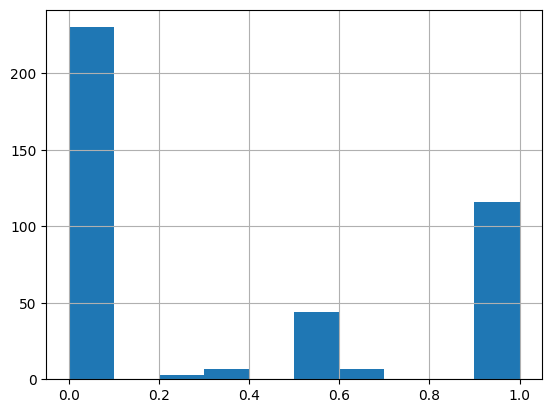

In [20]:
pllshares["num_sg"].hist()

In [21]:
shapiro(pllshares["num_sg"])

ShapiroResult(statistic=np.float64(0.6957434865767785), pvalue=np.float64(1.8129801901462983e-26))

<Axes: >

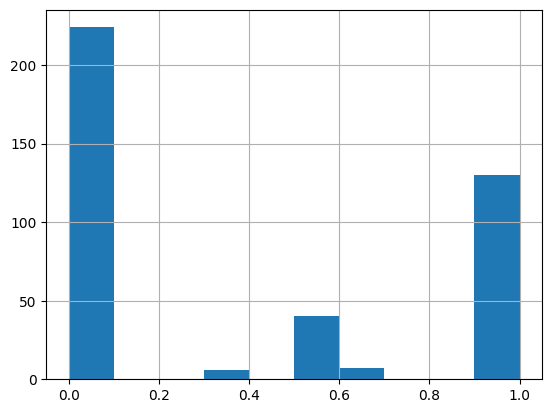

In [22]:
pllshares["num_pl"].hist()

In [23]:
shapiro(pllshares["num_pl"])

ShapiroResult(statistic=np.float64(0.6946936774622854), pvalue=np.float64(1.6609343009060926e-26))

The Wilcoxon test, which is often considered a t-paired test alternative for non-normal data, could not be conducted either, since it is based on the ranks of the difference between the paired measurements, and most of the difference are zeros, and they are so many that not even Pratt's corrections could help.

<Axes: >

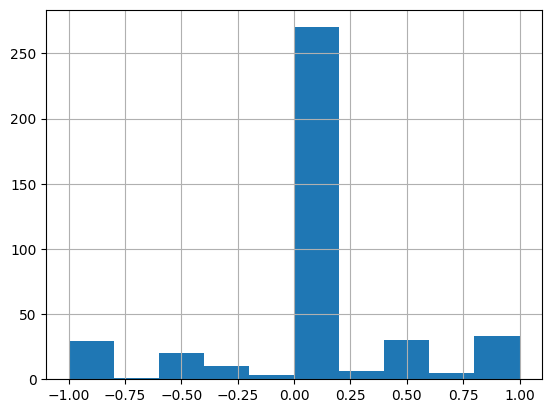

In [24]:
(pllshares["num_pl"] - pllshares["num_sg"]).hist()

# Study 2

Study 2 expands study 1 and investigates the ExtPE for each individual N1 in each of the nine data samples, following Pankratz 2017. It aims at answering whether certain N1s are more sensitive to the ExtPE than the others.

Study 2 contributes to **Hypothesis 1**. Expected outcome: ExtPE will be confirmed on less "contaminated" datasets in the lower frequency setting with some N1s.

It also indirectly contributes to **Hypothesis 2** and **Hypothesis 3**. Expected outcome: the increase in the level of "contamination" and frequency will result in fading/vanishing ExtPE with some or all N1s.

In [22]:
st2dir = os.path.join(resdir, "study_2")
os.makedirs(st2dir, exist_ok=True)

In [23]:
n1s = sp18_sample["n1"].unique()
n1s

<StringArray>
[      'apfel',         'bad',        'ball',        'bett',        'bild',
       'brett',       'brief',        'buch',       'bucht',       'dämon',
          'ei', 'eigenschaft',     'element',        'frau',       'gerät',
    'geräusch',    'geschenk',     'gitarre',        'hand',        'haus',
        'hemd',        'hund',       'katze',        'kind',     'kommune',
        'lied',        'loch',      'mutter',       'nagel',      'nation',
         'ohr',      'person',     'produkt',   'projektor',         'rad',
     'schloss',     'schwert',   'schwester',       'sonne',       'stadt',
       'vater',       'vogel',         'weg',        'wurm',        'zahn',
       'zitat']
Length: 46, dtype: str

In [25]:
chi2_summaries = defaultdict(dict)
sign_n1s = []
with tqdm(
    total=len(datasets) * len(freq_levels) * len(n1s), 
    desc="ExtPE Study 2"
) as pbar:

    # three datasets x ...
    for sample_sfx, sp18_sample in datasets:
        
        # ... x 46 N1s x ...
        for n1 in n1s:

            chi2dfs = []
            is_sign = False

            # ... x three levels of frequency
            for freq_sfx, freq_threshold in freq_levels:

                sp18_subsample = sp18_sample[
                    (sp18_sample["wc"] >= freq_threshold) &
                    (sp18_sample["n1"] == n1)
                ]

                m = len(sp18_subsample["n1"].unique())

                try:
                    # not providing the directory; only 
                    # significant N1s will be saved later
                    *_, chi2df = lrun_onesample_study(sp18_subsample)
                    # increased original p-value to account for small sample sizes;
                    # however, when a large family of significance tests is run
                    # simultaneously, there is a probability that some
                    # significant results will appear by chance; to account for that,
                    # we follow [schaefer_pankratz_2018:27] and apply Šidák’s
                    # correction; the corresponding R code is:
                    # adjust.p.sidak <- function(p, m) { 1-(1-p)^m };
                    chi2df["p_sidak"] = (1 - (1 - chi2df["p"]) ** m).round(3)
                    # will become the colname in chi2_summary
                    chi2df.name = freq_sfx
                    chi2dfs.append(chi2df)
                    # use the corrected p-value!
                    if chi2df["p_sidak"] < 0.1:
                        sign_n1s.append(n1)
                except (KeyError, ValueError):
                    # `all_nipe_npll` is missing a few N1s;
                    # otherwise, after freq filtering
                    # not all CCs have valid contingency tables
                    pass

                pbar.update(1)
            
            # summary over the freq levels for one N1 in one dataset
            chi2_summary = pd.concat(chi2dfs, axis=1) if chi2dfs else None
            chi2_summaries[n1][sample_sfx] = chi2_summary

ExtPE Study 2: 100%|██████████| 414/414 [00:20<00:00, 19.77it/s]


In [28]:
os.makedirs(os.path.join(st2dir, "all"), exist_ok=True)
for n1, chi2_sum in chi2_summaries.items():
    # 3D res DF: dataset x freq x chi2 test metrics
    chi2_summary = pd.concat(chi2_sum.values(), keys=chi2_sum.keys())  \
        .swaplevel(0, 1)    \
        .sort_index(level=0, sort_remaining=False)  \
        .reindex(chi2df.index, level=0)
    savetsv(chi2_summary, os.path.join(st2dir, "all"), n1)

Only three N1s reached a marginal statistical significance at sig = 0.1 (increased p-value threshold to account for the small sample sizes).

In [29]:
set(sign_n1s)

{'apfel', 'bucht', 'person'}

In [26]:
# TODO: optimize
# rerun significant N1s to save the outputs
chi2_summaries = defaultdict(dict)
with tqdm(
    total=len(datasets) * len(freq_levels) * len(set(sign_n1s)), 
    desc="ExtPE Study 2: significant N1s"
) as pbar:
    
    # three datasets x ...
    for sample_sfx, sp18_sample in datasets:

        # ... x 3 N1s x ...
        for n1 in sorted(set(sign_n1s)):

            chi2dfs = []
            outdir = os.path.join(st2dir, n1, sample_sfx)
            is_sign = False

            # ... x three levels of frequency
            for freq_sfx, freq_threshold in freq_levels:

                sp18_subsample = sp18_sample[
                    (sp18_sample["wc"] >= freq_threshold) &
                    (sp18_sample["n1"] == n1)
                ]

                try:
                    *_, chi2df = lrun_onesample_study(
                        sp18_subsample,
                        os.path.join(outdir, freq_sfx)
                    )
                    # increased original p-value to account for small sample sizes;
                    # however, when a large family of significance tests is run
                    # simultaneously, there is a probability that some
                    # significant results will appear by chance; to account for that,
                    # we follow [schaefer_pankratz_2018:27] and apply Šidák’s
                    # correction; the corresponding R code is:
                    # adjust.p.sidak <- function(p, m) { 1-(1-p)^m } 
                    chi2df["p_sidak"] = (1 - (1 - chi2df["p"]) ** m).round(3)
                    # will become the colname in chi2_summary
                    chi2df.name = freq_sfx
                    chi2dfs.append(chi2df)
                except (KeyError, ValueError):
                    # `all_nipe_npll` is missing a few N1s;
                    # otherwise, after freq filtering
                    # not all CCs have valid contingency tables
                    pass

                pbar.update(1)
                
            # summary over the freq levels for one N1 in one dataset
            chi2_summary = pd.concat(chi2dfs, axis=1) if chi2dfs else None
            if chi2_summary is not None:
                savetsv(chi2_summary, outdir, "chi2_summary")
            chi2_summaries[n1][sample_sfx] = chi2_summary

ExtPE Study 2: significant N1s: 100%|██████████| 27/27 [00:01<00:00, 19.76it/s]


In [27]:
chi2_summaries_conc = {}
for n1, chi2_sum in chi2_summaries.items():
    # 3D res DF: dataset x freq x chi2 test metrics
    chi2_summary = pd.concat(chi2_sum.values(), keys=chi2_sum.keys())  \
        .swaplevel(0, 1)    \
        .sort_index(level=0, sort_remaining=False)  \
        .reindex(chi2df.index, level=0)
    savetsv(chi2_summary, os.path.join(st2dir, n1), "chi2_summary")
    chi2_summaries_conc[n1] = chi2_summary

Below is a table with the results of the Chi2 test for N1s that achieved a marginal statistical significance at sig = 0.1 (increased p-value threshold to account for the smaller sample sizes).

In [28]:
chi2_summary = pd.concat(chi2_summaries_conc, axis=1)
savetsv(chi2_summary, st2dir, "chi2_summary")
chi2_summary

apfel                   bucht  person
                                 lfreq   mfreq   hfreq   lfreq   lfreq
N             ic_alt_nipe_npll  46.000  33.000  26.000     NaN     NaN
              ic_alt_nipe       46.000  33.000  26.000  46.000  51.000
              ic_alt            52.000  33.000  26.000  49.000  66.000
df            ic_alt_nipe_npll   1.000   1.000   1.000     NaN     NaN
              ic_alt_nipe        1.000   1.000   1.000   1.000   1.000
              ic_alt             1.000   1.000   1.000   1.000   1.000
chi2          ic_alt_nipe_npll   3.242   0.136   1.187     NaN     NaN
              ic_alt_nipe        3.242   0.136   1.187   2.716   3.780
              ic_alt             2.233   0.136   1.187   2.366   3.967
p             ic_alt_nipe_npll   0.072   0.712   0.276     NaN     NaN
              ic_alt_nipe        0.072   0.712   0.276   0.099   0.052
              ic_alt             0.135   0.712   0.276   0.124   0.046
cramer_v      ic_alt_nipe_npll   0.265   0.064   0.214     NaN     NaN
              ic_alt_nipe        0.265   0.064   0.214   0.243   0.272
              ic_alt             0.207   0.064   0.214   0.220   0.245
resids_cong   ic_alt_nipe_npll   2.107   0.821   1.323     NaN     NaN
              ic_alt_nipe        2.107   0.821   1.323   1.951   2.228
              ic_alt             1.776   0.821   1.323   1.836   2.246
resids_incong ic_alt_nipe_npll  -2.107  -0.821  -1.323     NaN     NaN
              ic_alt_nipe       -2.107  -0.821  -1.323  -1.951  -2.228
              ic_alt            -1.776  -0.821  -1.323  -1.836  -2.246
p_sidak       ic_alt_nipe_npll   0.072   0.712   0.276     NaN     NaN
              ic_alt_nipe        0.072   0.712   0.276   0.099   0.052
              ic_alt             0.135   0.712   0.276   0.124   0.046

'Apfel' reaches marginal significance only in the `ic_alt_nipe_npll` and `ic_alt_nipe` datasets, and only in the low frequency setting. 'Bucht' reaches marginal significance only in the `ic_alt_nipe` dataset, and only in the low frequency setting. 'Person' reaches marginal significance only in the `ic_alt_nipe` and the `ic_alt` datasets, and only in the low frequency setting.

In [29]:
chi2_summary.loc[["p", "cramer_v"]]

apfel                bucht person
                           lfreq  mfreq  hfreq  lfreq  lfreq
p        ic_alt_nipe_npll  0.072  0.712  0.276    NaN    NaN
         ic_alt_nipe       0.072  0.712  0.276  0.099  0.052
         ic_alt            0.135  0.712  0.276  0.124  0.046
cramer_v ic_alt_nipe_npll  0.265  0.064  0.214    NaN    NaN
         ic_alt_nipe       0.265  0.064  0.214  0.243  0.272
         ic_alt            0.207  0.064  0.214  0.220  0.245

The reason N1s 'Person' and 'Bucht' have only an `lfreq` column is because after frequency filtering, the remaining compounds with these N1s ceased to alternate between non-pluralic and pluralic linker in different numbers, always inserting the latter. That led to corrupted contingency tables, so no result could be obtained for these N1s in the moderate/high frequency setting. It is, however, clear that no alternation means no ExtPE whatsoever.

In [31]:
sign_n1s_mfreq = ic_alt_nipe[
	(ic_alt_nipe["n1"].isin(["person", "bucht"])) &
	(ic_alt_nipe["wc"] >= 20)
]
sign_n1s_mfreq

,gecodb,n1,n2,n1_pl_marker,n1_sem,n2_num,is_linker_pl,wc,context,context_id
const_comb,,,,,,,,,,
person+aufzug,person_+en_aufzug,person,aufzug,_+en_,ind,sg,True,2285,Auch eine Anschlußmöglichkeit für ein Notrufte...,80322f47-b8c5-4cef-8913-3b9a9e515355
person+aufzug,person_+en_aufzug,person,aufzug,_+en_,ind,pl,True,2285,Die Beförderung von einem Stockwerk ins nächst...,1a2a2864-4c16-47a1-9b2f-1eaae254e365
person+beförderung,person_+en_beförderung,person,beförderung,_+en_,ind,pl,True,3492,Wir wünschen viel Spaß und Erfolg beim beobach...,77649f9a-080e-4b48-b50b-5fb469051cd0
person+beförderung,person_+en_beförderung,person,beförderung,_+en_,ind,sg,True,3492,"""""""Schon jetzt bewertet dabei eine namhafte Fr...",2ec1e9e5-d5cb-4cf1-8d20-c19aecaca27d
person+beschreibung,person_+en_beschreibung,person,beschreibung,_+en_,ind,sg,True,7886,"Der ist mMn momentan nicht so wichtig , um obe...",6dcd445a-9d23-425e-8d9f-97586746bb91
person+beschreibung,person_+en_beschreibung,person,beschreibung,_+en_,ind,pl,True,7886,Boten 127 ( Szenario ) bis auf weiteres aus de...,6c3c7ac4-ffa7-4758-8c4e-714f8e3e956e
person+fähre,person_+en_fähre,person,fähre,_+en_,ind,pl,True,2294,"Dann fliegt man meist über Nürnberg , Palma od...",0405e0fc-5352-414c-ae50-a77845bf353c
person+fähre,person_+en_fähre,person,fähre,_+en_,ind,sg,True,2294,Vorbei an weitläufigen Wiesen und Weiden errei...,e283c401-aba8-48e9-b274-9e13abf76d62
person+gesellschaft,person_+en_gesellschaft,person,gesellschaft,_+en_,ind,pl,True,7535,"Bei Geschäften , welche den Kernbereich des Un...",b8363426-b900-4243-b69d-8c87d5abd02b


In [32]:
sign_n1s_mfreq["is_linker_pl"].unique()

array([ True])

Furthermore, N1s 'Person' and 'Bucht' were removed from the `ic_alt_nipe_npll` dataset as they may attach the PLL under non-pluralic constraints. Being two of the only three significant N1s found in the data, these N1s should contribute noticeably into the overall effect, which explains why the "cleanest" `ic_alt_nipe_npll` has the weakest ExtPE. This speaks strongly against **Hypothesis 2**.

#### Study 2 Results

> Summary: Study 2 provides partial direct evidence **for Hypothesis 1**, provides indirect evidence **against Hypothesis 2**, and provides indirect evidence **for Hypothesis 3**.

Study 2 contributes to **Hypothesis 1**. Expected outcome: ExtPE will be confirmed on less "contaminated" datasets in the lower frequency setting with some N1s.

Actual outcome: N1s 'Apfel' undergoes the ExtPE in the desired direction at marginal significance level sig = 0.1 (increased p-value threshold to account for the small sample sizes), but only in `ic_alt_nipe_npll` and `ic_alt_nipe` and only in the low frequency setting ($χ2 = 3.242, df = 1, p = 0.072, v = 0.265$). N1 'Bucht' undergoes the ExtPE in the desired direction at significance level sig = 0.1 in `ic_alt_nipe` and only in the low frequency setting ($χ2 = 2.716, df = 1, p = 0.099, $v = 0.243$).  N1 'Person' undergoes the ExtPE in the desired direction at significance level close to sig = 0.05 in `ic_alt_nipe` and `ic_alt`, but, again, only in the low frequency setting ($χ2 = 3.967, df = 1, p = 0.046, v = 0.245$).

---

It also indirectly contributes to **Hypothesis 2** and **Hypothesis 3**. Expected outcome: the increase in the level of "contamination" and frequency will result in fading/vanishing ExtPE with some or all N1s.

Actual outcome: the fact that the marginal significance disappears with 'Apfel' and 'Bucht' in the most "contaminated" dataset `ic_alt` indirectly points towards the effect of the problematic groups on the ExtPE. However, removal of N1s 'Person' and 'Bucht' from `ic_alt_nipe_npll` speaks strongly against the problematic groups effect, since these are two of out three N1s that contribute to the ExtPE the most. The fact that the (marginal) significance disappears with all three N1s in the moderate/high frequency settings indirectly points towards the effect of frequency on the ExtPE.

---

The significant results of N1s 'Apfel' and 'Person' confirm finding of Pankratz 2017. However, none of the other six "significant" N1s reported by Pankratz 2017 reach statistical significance in any of the nine data samples.

# Studies 3 & 4

In [37]:
label_1_calc_shares, label_2_calc_shares = label_1, label_2

def lrun_twosamples_study(
	sample_1: pd.DataFrame,
	sample_2: pd.DataFrame,
	label_1: str,
	label_2: str,
	target_predictor: str,
	outdir: Optional[str]=None
):
	return run_twosamples_study(
		sample_1,
		sample_2,
		groupby=groupby,
		target_col=target_col,
		label_1_calc_shares=label_1_calc_shares,
		label_2_calc_shares=label_2_calc_shares,
		label_1=label_1,
		label_2=label_2,
		target_predictor=target_predictor,
		outdir=outdir
	)

## Study 3

Study 3 focuses on the distribution of non-pluralic and pluralic linker in compounds in the Sg form only. It contrasts the distribution in the "cleanest" `ic_alt_nipe_npll` vs the two other datasets with an increasing level of "contamination" by the problematic groups.

Study 3 contributes to **Hypothesis 2** and provides a more detailed account of the effect of the problematic groups on ExtPE. Expected outcome: more "contaminated" datasets will have a larger share of pluralic linkers in the Sg form (due to more possible sources).

In [38]:
st3dir = os.path.join(resdir, "study_3")
os.makedirs(st3dir, exist_ok=True)

In [39]:
# problematic groups effect; compare `ic_alt_nipe_npll`
# with the other two datasets
with tqdm(
    total=len(datasets) - 1,
    desc="ExtPE Study 3"
) as pbar:

    chi2dfs = []

    # two dataset pairings
    for sample_sfx, sp18_sample_1 in datasets[1:]:

        # we expect a larger pluralic linker share in 
        # the more "contaminated" sample in Sg form because
        # they should have more sources for the pluralic linker
        # to appear in the Sg form
        *_, chi2df = lrun_twosamples_study(
            sp18_sample_1,
            ic_alt_nipe_npll,
            label_1=sample_sfx,
            label_2=datasets[0][0],
            # look at the distr in the Sg form
            # target_predictor="num_sg",    # removed pfx here
            target_predictor="sg",
            outdir=os.path.join(st3dir, f"vs_{sample_sfx}")
        )
        # will become the colname in chi2_summary
        chi2df.name = f"vs_{sample_sfx}"
        chi2dfs.append(chi2df)
        
        pbar.update(1)

    chi2_summary = pd.concat(chi2dfs, axis=1)
    savetsv(chi2_summary, st3dir, "chi2_summary")

ExtPE Study 3: 100%|██████████| 2/2 [00:07<00:00,  3.97s/it]


We find that `ic_alt` has a larger share of pluralic linker in the compounds in the Sg form, reaching a statistical significance at sig = 0.005.

In [40]:
chi2_summary

,vs_ic_alt_nipe,vs_ic_alt
N,1517.000,1729.000
df,1.000,1.000
chi2,1.430,12.539
p,0.232,0.000
cramer_v,0.031,0.085
resids_cong,1.251,3.593
resids_incong,-1.251,-3.593


#### Study 3 Results

> Summary: Study 3 provides direct evidence **for Hypothesis 2**.

Study 3 contributes to **Hypothesis 2**. Expected outcome: more "contaminated" datasets will have a larger share of pluralic linkers in the Sg form (due to more possible sources).

Actual outcome: while comparison of the linker distributions over the compounds in the Sg form in `ic_alt_nipe_npll` vs `ic_alt_nipe` did not produce statistical significance, comparing the "cleanest" `ic_alt_nipe_npll` and the most "contaminated" `ic_alt` reveals a statistically significant effect at sig = 0.005 ($χ2 = 12.539, df = 1, p \approx 0.0, v = 0.085$). The examination of the symmetrical (standardised) residuals reveals that the diverging data points followed the expected direction, that is, compounds in the Sg form in `ic_alt` have a larger share of pluralic linkers, and those in `ic_alt_nipe_npll` a smaller share of pluralic linkers, than expected by chance ($3.593$). This means that compounds in `ic_alt` have more sources for the pluralic linker to appear in the Sg form. The finding contradicts the indirect evidence against Hypothesis 2 from Studies 1 and 2 and does not confirm the effect.

## Study 4

Study 4 focuses on the distribution of non-pluralic and pluralic linker in compounds in the Pl form only. It contrasts the distribution in the low frequency setting vs the moderate/high frequency setting, within each of the three dataset.

Study 4 contributes to **Hypothesis 3** and provides a more detailed account of the effect of the frequency setting on ExtPE. Expected outcome: the share of the pluralic linkers in compounds in the Pl form will be larger in in the low frequency setting (since most of the ExtPE manifestations are a product of immediate language).

In [41]:
st4dir = os.path.join(resdir, "study_4")
os.makedirs(st4dir, exist_ok=True)

In [42]:
# frequency effect; compare `lfreq` to
# `mfreq`/`hreq` in each dataset
with tqdm(
    total=len(datasets) * (len(freq_levels) - 1),
    desc="ExtPE Study 4"
) as pbar:

    chi2_summaries = []

    # three datasets x ...
    for sample_sfx, sp18_sample_1 in datasets:

        chi2dfs = []
        outdir = os.path.join(st4dir, sample_sfx)

        # ... x two frequency level parings
        for freq_sfx, freq_threshold in freq_levels[1:]:

            sp18_sample_2 = sp18_sample_1[
                sp18_sample_1["wc"] >= freq_threshold
            ]

            try:
                # we expect a larger pluralic linker share
                # in the `lfreq` sample
                *_, chi2df = lrun_twosamples_study(
                    sp18_sample_1,
                    sp18_sample_2,
                    label_1="lfreq",
                    label_2=freq_sfx,
                    # look at the distr in the Sg form
                    # target_predictor="num_pl",    # removed pfx here
                    target_predictor="pl",
                    outdir=os.path.join(outdir, f"vs_{freq_sfx}")
                )
                # will become the colname in chi2_summary
                chi2df.name = f"vs_{freq_sfx}"
                chi2dfs.append(chi2df)
            except (KeyError, ValueError):
                # `all_nipe_npll` is missing a few N1s;
                # otherwise, after freq filtering
                # not all CCs have valid contingency tables
                pass

            pbar.update(1)

        # summary over the freq level pairings for one dataset
        chi2_summary = pd.concat(chi2dfs, axis=1) if chi2dfs else None
        if chi2_summary is not None:
            savetsv(chi2_summary, outdir, "chi2_summary")
        chi2_summaries.append(chi2_summary)

ExtPE Study 4: 100%|██████████| 6/6 [00:22<00:00,  3.79s/it]


In [43]:
# 3D res DF: dataset x freq pairing x chi2 test metrics
chi2_summary = pd.concat(chi2_summaries, keys=[p[0] for p in datasets])  \
    .swaplevel(0, 1)    \
    .sort_index(level=0, sort_remaining=False)  \
    .reindex(chi2df.index, level=0)
savetsv(chi2_summary, st4dir, "chi2_summary")
chi2_summary

vs_mfreq  vs_hfreq
N             ic_alt_nipe_npll   919.000   866.000
              ic_alt_nipe       1580.000  1494.000
              ic_alt            1876.000  1772.000
df            ic_alt_nipe_npll     1.000     1.000
              ic_alt_nipe          1.000     1.000
              ic_alt               1.000     1.000
chi2          ic_alt_nipe_npll     4.280     8.190
              ic_alt_nipe          1.718     2.933
              ic_alt               0.939     1.952
p             ic_alt_nipe_npll     0.039     0.004
              ic_alt_nipe          0.190     0.087
              ic_alt               0.332     0.162
cramer_v      ic_alt_nipe_npll     0.068     0.097
              ic_alt_nipe          0.033     0.044
              ic_alt               0.022     0.033
resids_cong   ic_alt_nipe_npll     2.138     2.935
              ic_alt_nipe          1.363     1.767
              ic_alt               1.016     1.446
resids_incong ic_alt_nipe_npll    -2.138    -2.935
              ic_alt_nipe         -1.363    -1.767
              ic_alt              -1.016    -1.446

The only comparison that produces statistically significant results at sig = 0.05 is that in `ic_alt_nipe_npll`. On other datasets, p-values decrease, and the Cramer's V values decrease consistently with increasing frequency.

In [44]:
chi2_summary.loc[["p", "cramer_v"]]

vs_mfreq  vs_hfreq
p        ic_alt_nipe_npll     0.039     0.004
         ic_alt_nipe          0.190     0.087
         ic_alt               0.332     0.162
cramer_v ic_alt_nipe_npll     0.068     0.097
         ic_alt_nipe          0.033     0.044
         ic_alt               0.022     0.033

### Study 4 Results

> Summary: Study 4 provides direct evidence **for Hypothesis 3** and indirect evidence **for Hypothesis 2**.

Study 4 contributes to **Hypothesis 4**. Expected outcome: the share of the pluralic linkers in compounds in the Pl form will be larger in in the low frequency setting (since most of the ExtPE manifestations are a product of immediate language).

Actual outcome: comparison of the linker distributions over the compounds in the Pl form in difference frequency settings produced statistical significance only in the `ic_alt_nipe_npll` dataset: low vs. moderate frequency reaches significance at sig = 0.05, and low vs. high frequency at sig = 0.005 (low vs. moderate: $χ2 = 4.28, df = 1, p = 0.039, v = 0.068$; low vs. high: $χ2 = 8.19, df = 1, p = 0.004, v = 0.097$). The examination of the symmetrical (standardised) residuals reveals that the diverging data points followed the expected direction, that is, compounds in the Pl form inserted pluralic linkers more frequently in the low frequency setting and less frequently in the moderate/high than expected by chance ($2.138$ and $2.935$, respectively). This finding supports the indirect evidence for Hypothesis 3 from Studies 1 and 2, and confirms the effect.

---

The fact that the more "contaminated" datasets did not exhibit a significant difference additionally speaks for Hypothesis 2 and may be explained by that the additional sources of pluralic linkers there erode the effect. This is attested by the fact that, while insignificant, the p-values still increase, and the Cramer's V values decrease there consistently with increasing frequency level.